In [ ]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import random
import numpy as np
import pandas as pd
import torch
import optuna
import protein_ss.dataset as ss_dataset
import protein_ss.plots as ss_plots
import protein_ss.modeling.classes as ss_classes
import protein_ss.modeling.train as ss_train
import protein_ss.modeling.predict as ss_predict

from IPython.display import display
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

c:\Users\Admin\Desktop\Course_Materials\protein_ss_mlm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-30 15:07:52.258 | INFO     | protein_ss.config:<module>:13 - PROJ_ROOT path is: C:\Users\Admin\Desktop\Course_Materials\protein_ss_mlm


cuda


In [ ]:
MAX_LEN = 512
MAX_TRAIN = 3000 # 2000 for train split, 1000 for val split

train_df = ss_dataset.download('training_hhblits.csv')
test_df = ss_dataset.download('CB513.csv')
display(train_df.head(5))
display(test_df.head(5))

train_df = ss_dataset.clean(train_df, MAX_LEN, SEED, MAX_TRAIN)
test_df = ss_dataset.clean(test_df, MAX_LEN, SEED)
print(train_df.shape)
print(test_df.shape)

all_labels = ''.join(train_df['dssp3']) # join all target sequences into 1 contiguous str
counts = pd.Series(list(all_labels)).value_counts() # split characters in contiguous str into list of elements -> convert to Series -> value_counts for count dist of state labels
freq = counts / counts.sum() # express int proportions
baseline = freq.max() # store baseline performance benchmark

display(freq) # majority class baseline performance benchmark: C at 0.420512

,input,dssp3,dssp8,disorder,cb513_mask
0,MKTAYIAKQRQISFVKSHFSRQLEERLGLIEVQAPILSRVGDGTQD...,CCCCHHHHHHHHHHHHHHHHHHHHHHHCEEECCCCCEEECCCCCCC...,CCCCHHHHHHHHHHHHHHHHHHHHHHHCEEECCCCSEEETTSSCSC...,0.0 0.0 0.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
1,SRMPSPPMPVPPAALFNRLLDDLGFSAGPALCTMLDTWNEDLFSAL...,CCCCCCCCCCCHHHHHHHHHHHHCCCCHHHHHHHHHHCCCCCCCCC...,CCSCCCCCCCCHHHHHHHHHHHHTCTTHHHHHHHHHHCCCCCSTTS...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
2,RRSPPADAIPKSKKVKVSHRSHSTEPGLVLTLGQGDVGQLGLGENV...,CCCCCCCCCCCCCCCCCCCCCCCCCCEEEEEEEECCCCCCCCCCCC...,CCCCCCCCCCCCCCCCCCCTTCCCCCBEEEEEEECTTSTTCSCTTC...,0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
3,GSAGEDVGAPPDHLWVHQEGIYRDEYQRTWVAVVEEETSFLRARVQ...,CCCCCCCCCCCCEEEEEECCEEEECCCCEEEEEEEECCCCEEEEEE...,CCCCCCCCCCCSEEEEEETTEEEETTSCEEEEEEEECSSCEEEEEE...,0.0 0.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
4,GDEEKRNRAITARRQHLKSVMLQIAATELEKEEGRREAEKQNYLAEH,CCCCHHHHHHHHHHHHHHHHHHHHHHHHHHHCCCCCCCCCCCCCCCC,CCCCHHHHHHHHHHHHHHHHHHHHHHHHHHHTCCCCCCCCCCCCCCC,0.0 0.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....


,input,dssp3,dssp8,disorder,cb513_mask
0,RTDCYGNVNRIDTTGASCKTAKPEGLSYCGVSASKKIAERDLQAMD...,CCCCCCCHHHCCCCCECHHHHCCCCCCCCEHHHHHHHHHHCHHHHH...,CCCTTCCGGGSCCCCBCHHHHTTTTCSCCBHHHHHHHHHHTHHHHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
1,GKITFYEDRGFQGRHYECSSDHSNLQPYFSRCNSIRVDSGCWMLYE...,CEEEEEEECCCEEEEEEECCCECCCCCCCCCCCEEEEEECEEEEEC...,CEEEEEEETTTEEEEEEECSCBSCCTTTCSCCSEEEEEESEEEEES...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
2,MFKVYGYDSNIHKCVYCDNAKRLLTVKKQPFEFINIMPEKGVFDDE...,CEEEEECCCCCCCCHHHHHHHHHHHHCCCCEEEEECCCECCECCHH...,CEEEEECCTTTSCCHHHHHHHHHHHHTTCCEEEEESCSBTTBCCHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
3,APAFSVSPASGASDGQSVSVSVAAAGETYYIAQCAPVGGQDACNPA...,CCEEEEECCCCCCCCCEEEEEEECCCCEEEEEEECEECCEECCCCC...,CCEEEEECCSSCCSSCEEEEEEESCCSEEEEEEECEETTEECCCTT...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
4,TPAFNKPKVELHVHLDGAIKPETILYFGKKRGIALPADTVEELRNI...,CCCCCCCEEEEEEEHHHCCCHHHHHHHHHHHCCCCCCCCHHHHHHH...,CCSCCSCEEEEEEEGGGSCCHHHHHHHHHHHTCCCSCSSHHHHHHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....


(3000, 2)
(443, 2)


C    0.420512
H    0.362535
E    0.216953
Name: count, dtype: float64

In [3]:
EPOCHS = 35
BATCH_SIZE = 32
AA = 'ACDEFGHIKLMNPQRSTVWY' # standard IUPAC letter for all 20 amino acids
AA_TO_IDX = {a:i for i, a in enumerate(AA)} # tokenizer mapping AA letter to index following 0-based indexing
X_IDX = 20 # index unk residues
N_VOCAB = len(AA_TO_IDX)# 20; excludes unk residue X, mask or pad

PAD_IDX = 21 # index for padding tokens
MASK_IDX = 22
MLM_VOCAB = N_VOCAB + 3 # 23; 20 standard residues + unk X residue + 1 padding + 1 mask

LABELS = ''.join(freq.index)
LABELS_TO_IDX = {s: i for i, s in enumerate(LABELS)}
IGNORE_IDX = -100

In [4]:
train_split, val_split = train_test_split(train_df, test_size=1/3, random_state=SEED, shuffle=True) # expect 2000 train examples, 1000 val examples
generator = torch.Generator().manual_seed(SEED) # cpu generator

train_dataset = ss_dataset.MLMDataset(train_split, AA_TO_IDX, X_IDX)
val_dataset = ss_dataset.MLMDataset(val_split, AA_TO_IDX, X_IDX)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=lambda batch: ss_dataset.mlm_collate(batch, PAD_IDX, IGNORE_IDX, MASK_IDX, X_IDX, n_vocab=N_VOCAB))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=lambda batch: ss_dataset.mlm_collate(batch, PAD_IDX, IGNORE_IDX, MASK_IDX, X_IDX, generator, n_vocab=N_VOCAB))

In [5]:
study = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner(n_warmup_steps=5))
study.optimize(lambda trial:ss_train.objective(trial, train_loader, val_loader, MAX_LEN, MLM_VOCAB, EPOCHS, PAD_IDX, IGNORE_IDX, SEED, DEVICE, generator, n_vocab=N_VOCAB), n_trials=20)
best_params = study.best_params
print(f"Best Masked Token Accuracy was {study.best_value:.3f} from hyperparameter set: {best_params}")

[I 2026-10-30 15:07:55,294] A new study created in memory with name: no-name-14ba4a5f-ff85-47c3-aa51-5e5c989a926d
c:\Users\Admin\Desktop\Course_Materials\protein_ss_mlm\.venv\Lib\site-packages\torch\autograd\graph.py:841: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:899.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
[I 2026-10-30 15:09:37,646] Trial 0 finished with value: 0.18859687447547913 and parameters: {'d_model': 256, 'nhead': 2, 'num_layers': 2, 'lr': 0.000555020055319129, 'dropout': 0.20913344396607716}. Best is trial 0 with value: 0.18859687447547913.
[I 2026-10-30 15:13:44,439] Trial 1 finished with value: 0.18231424689292908 and parameters: {'d_model': 

Best Masked Token Accuracy was 0.194 from hyperparameter set: {'d_model': 256, 'nhead': 4, 'num_layers': 3, 'lr': 0.0007684303029151955, 'dropout': 0.026623747086050517}


Epochs:   0%|          | 0/35 [00:00<?, ?it/s]

Epochs:   3%|▎         | 1/35 [00:04<02:32,  4.49s/it]

Epoch: 1
	Train Loss: 2.763
	Val Loss: 2.721
	Masked Token Accuracy: 0.176



Epochs:  14%|█▍        | 5/35 [00:22<02:15,  4.50s/it]

Epoch: 5
	Train Loss: 2.694
	Val Loss: 2.700
	Masked Token Accuracy: 0.181



...

Epochs:  71%|███████▏  | 25/35 [01:52<00:45,  4.51s/it]

Epoch: 25
	Train Loss: 2.671
	Val Loss: 2.676
	Masked Token Accuracy: 0.190



Epochs:  86%|████████▌ | 30/35 [02:14<00:22,  4.50s/it]

Epoch: 30
	Train Loss: 2.668
	Val Loss: 2.675
	Masked Token Accuracy: 0.189



Epoch: 35
	Train Loss: 2.668
	Val Loss: 2.675
	Masked Token Accuracy: 0.189



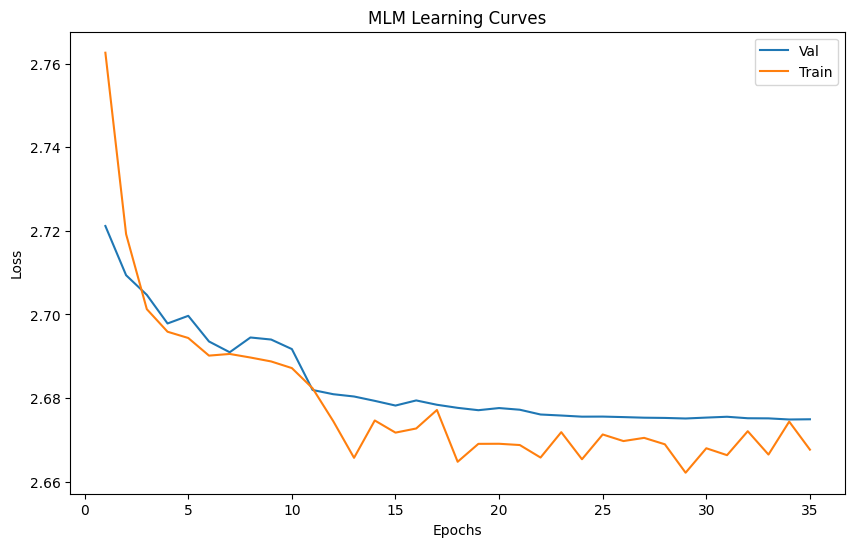

Best Epoch: 29
	Train Loss: 2.662
	Val Loss: 2.675
	Best Masked Token Accuracy: 0.190


In [6]:
out_dict = ss_train.train_val_loop(train_loader, val_loader, **best_params, max_len=MAX_LEN, mlm_vocab=MLM_VOCAB, epochs=EPOCHS, padding_idx=PAD_IDX, ignore_idx=IGNORE_IDX, seed=SEED, device=DEVICE, generator=generator, n_vocab=N_VOCAB)
train_epoch_losses = out_dict['train_epoch_losses']
val_epoch_losses = out_dict['val_epoch_losses']
best_epoch = out_dict['best_epoch']
best_eval_metric = out_dict['best_eval_metric']
encoder = out_dict['model']

ss_plots.plot_learning_curves(train_epoch_losses, val_epoch_losses, 'MLM Learning Curves')
print(f"Best Epoch: {best_epoch + 1}\n\tTrain Loss: {train_epoch_losses[best_epoch]:.3f}\n\tVal Loss: {val_epoch_losses[best_epoch]:.3f}\n\tBest Masked Token Accuracy: {best_eval_metric:.3f}")

In [7]:
ss_train_dataset = ss_dataset.SecondaryStructureDataset(train_split, AA_TO_IDX, LABELS_TO_IDX, IGNORE_IDX, X_IDX)
ss_val_dataset = ss_dataset.SecondaryStructureDataset(val_split, AA_TO_IDX, LABELS_TO_IDX, IGNORE_IDX, X_IDX)

ss_train_loader = DataLoader(ss_train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=lambda batch: ss_dataset.collate(batch, PAD_IDX, IGNORE_IDX))
ss_val_loader = DataLoader(ss_val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=lambda batch: ss_dataset.collate(batch, PAD_IDX, IGNORE_IDX))

In [8]:
all_train_labels = ''.join(train_split['dssp3']) # training labels only!
all_label_idx = np.array([LABELS_TO_IDX[label] for label in list(all_train_labels)], dtype=np.int64)
class_weights = compute_class_weight(class_weight='balanced', classes=np.arange(len(LABELS)), y=all_label_idx)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
frozen_encoder = ss_classes.FrozenMLMEncoder(encoder).to(DEVICE) # always set to eval mode

In [9]:
cnn_bilstm_study = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner(n_warmup_steps=5))
cnn_bilstm_study.optimize(lambda trial: ss_train.cnn_bilstm_objective(trial, ss_train_loader, ss_val_loader, weights_tensor, frozen_encoder, EPOCHS, IGNORE_IDX, SEED, DEVICE, len(LABELS)), n_trials=20)
cnn_bilstm_best_params = cnn_bilstm_study.best_params
print(f"Best MCC was {cnn_bilstm_study.best_value:.3f} from hyperparameter set: {cnn_bilstm_best_params}")

[I 2026-10-30 15:46:00,366] A new study created in memory with name: no-name-cf1d03fc-3940-44eb-9c99-5529c6400063
[I 2026-10-30 15:50:00,120] Trial 0 finished with value: 0.5246661305427551 and parameters: {'kernel_size': 3, 'hidden_size': 64, 'conv_layers': 2, 'lr': 0.00032094379612747104, 'dropout': 0.4091819882019297, 'weight_decay': 0.001124603876970139}. Best is trial 0 with value: 0.5246661305427551.
[I 2026-10-30 15:54:00,758] Trial 1 finished with value: 0.550381600856781 and parameters: {'kernel_size': 5, 'hidden_size': 64, 'conv_layers': 3, 'lr': 0.0005560924453645729, 'dropout': 0.23039171545881976, 'weight_decay': 0.0003461196184793965}. Best is trial 1 with value: 0.550381600856781.
[I 2026-10-30 15:58:04,262] Trial 2 finished with value: 0.5485410094261169 and parameters: {'kernel_size': 9, 'hidden_size': 64, 'conv_layers': 3, 'lr': 0.0006912131270078388, 'dropout': 0.1616019797857144, 'weight_decay': 0.00805053193033837}. Best is trial 1 with value: 0.550381600856781.
[I

Best MCC was 0.553 from hyperparameter set: {'kernel_size': 5, 'hidden_size': 64, 'conv_layers': 3, 'lr': 0.0015464824559438142, 'dropout': 0.20207556610393018, 'weight_decay': 0.0005047533777588664}


Epochs:   3%|▎         | 1/35 [00:07<03:59,  7.06s/it]

Epoch: 1
	Train Loss: 0.920
	Val Loss: 0.819
	Val MCC: 0.445
	Val Acc: 0.633



Epochs:  14%|█▍        | 5/35 [00:35<03:34,  7.14s/it]

Epoch: 5
	Train Loss: 0.746
	Val Loss: 0.725
	Val MCC: 0.516
	Val Acc: 0.680



Epochs:  29%|██▊       | 10/35 [01:11<02:56,  7.07s/it]

...

Epochs:  71%|███████▏  | 25/35 [02:57<01:10,  7.07s/it]

Epoch: 25
	Train Loss: 0.639
	Val Loss: 0.688
	Val MCC: 0.540
	Val Acc: 0.691



Epochs:  86%|████████▌ | 30/35 [03:33<00:35,  7.09s/it]

Epoch: 30
	Train Loss: 0.624
	Val Loss: 0.708
	Val MCC: 0.545
	Val Acc: 0.701



Epoch: 35
	Train Loss: 0.604
	Val Loss: 0.684
	Val MCC: 0.551
	Val Acc: 0.705



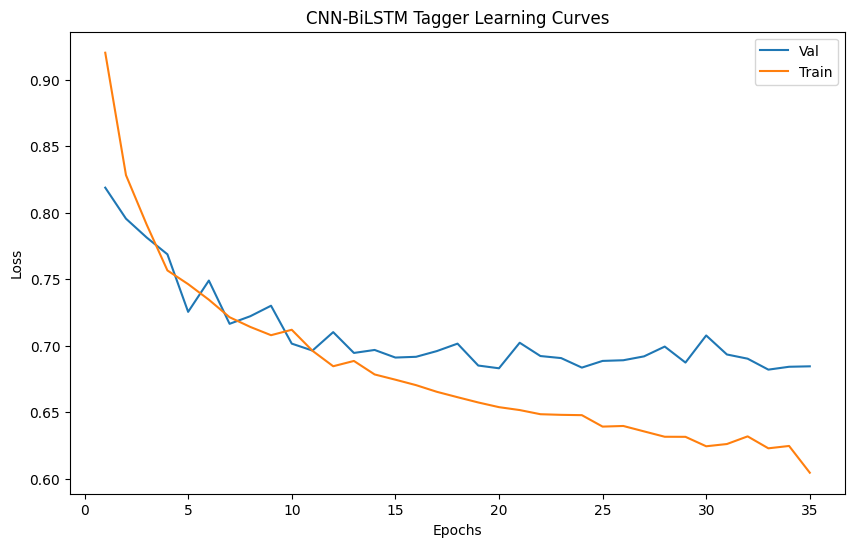

Best Epoch: 35
	Train Loss: 0.604
	Val Loss: 0.684
	Best MCC: 0.551
	Best Epoch Acc: 0.705



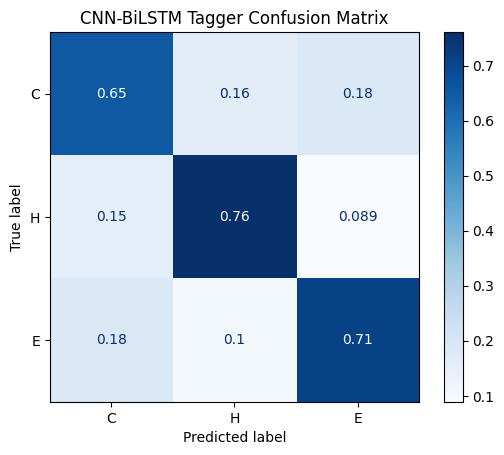

              precision    recall  f1-score   support

           C       0.74      0.65      0.70     95860
           H       0.75      0.76      0.75     81836
           E       0.59      0.71      0.64     49853

    accuracy                           0.70    227549
   macro avg       0.69      0.71      0.70    227549
weighted avg       0.71      0.70      0.71    227549



In [10]:
cnn_bilstm_out_dict = ss_train.cnn_bilstm_train_val_loop(ss_train_loader, ss_val_loader, weights_tensor, frozen_encoder, EPOCHS, IGNORE_IDX, DEVICE, **cnn_bilstm_best_params, num_classes=len(LABELS))
cnn_bilstm_train_epoch_losses = cnn_bilstm_out_dict['train_epoch_losses']
cnn_bilstm_val_epoch_losses = cnn_bilstm_out_dict['val_epoch_losses']
cnn_bilstm_best_epoch = cnn_bilstm_out_dict['best_epoch']
cnn_bilstm_best_eval_metric = cnn_bilstm_out_dict['best_eval_metric']
cnn_bilstm_best_epoch_acc = cnn_bilstm_out_dict['best_epoch_acc']
cnn_bilstm_best_true = cnn_bilstm_out_dict['best_true']
cnn_bilstm_best_preds = cnn_bilstm_out_dict['best_preds']
cnn_bilstm_model = cnn_bilstm_out_dict['model']

ss_plots.plot_learning_curves(cnn_bilstm_train_epoch_losses, cnn_bilstm_val_epoch_losses, 'CNN-BiLSTM Tagger Learning Curves')
print(f"Best Epoch: {cnn_bilstm_best_epoch + 1}\n\tTrain Loss: {cnn_bilstm_train_epoch_losses[cnn_bilstm_best_epoch]:.3f}\n\tVal Loss: {cnn_bilstm_val_epoch_losses[cnn_bilstm_best_epoch]:.3f}\n\tBest MCC: {cnn_bilstm_best_eval_metric:.3f}\n\tBest Epoch Acc: {cnn_bilstm_best_epoch_acc:.3f}\n")

ss_plots.cm_and_class_report(cnn_bilstm_best_true, cnn_bilstm_best_preds, LABELS_TO_IDX, 'CNN-BiLSTM Tagger Confusion Matrix')

Test Set MCC: 0.527
Test Set Acc: 0.688



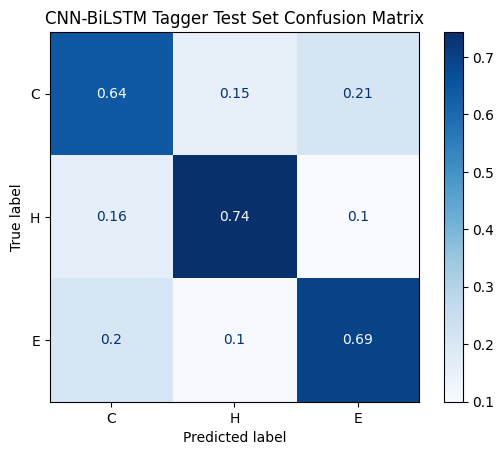

              precision    recall  f1-score   support

           C       0.74      0.64      0.69     43402
           H       0.75      0.74      0.75     34843
           E       0.54      0.69      0.61     21512

    accuracy                           0.69     99757
   macro avg       0.68      0.69      0.68     99757
weighted avg       0.70      0.69      0.69     99757



In [11]:
ss_test_dataset = ss_dataset.SecondaryStructureDataset(test_df, AA_TO_IDX, LABELS_TO_IDX, IGNORE_IDX, X_IDX)
ss_test_loader = DataLoader(ss_test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=lambda batch: ss_dataset.collate(batch, PAD_IDX, IGNORE_IDX))
ss_predict.cnn_bilstm_eval(cnn_bilstm_model, ss_test_loader, IGNORE_IDX, LABELS_TO_IDX, DEVICE, ss_plots.cm_and_class_report, 'CNN-BiLSTM Tagger Test Set Confusion Matrix', len(LABELS))